In [1]:

%pip install -q nltk scikit-learn textblob wordcloud tensorflow


In [3]:

# Q1
import re
import nltk
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

paragraph = """
I enjoy gardening because it makes ordinary afternoons peaceful and creative.
Growing vegetables teaches me patience and helps me understand nature.
My friends often visit the garden and admire the colorful flowers.
We share fresh tomatoes, exchange planting ideas, and learn from our mistakes.
Rainy mornings make the plants healthier while sunny days encourage new growth.
Gardening also reminds me that small efforts can create beautiful results.
"""

cleaned = re.sub(r'[^\w\s]', '', paragraph.lower())

print("Cleaned Text:\n", cleaned)


Cleaned Text:
 
i enjoy gardening because it makes ordinary afternoons peaceful and creative
growing vegetables teaches me patience and helps me understand nature
my friends often visit the garden and admire the colorful flowers
we share fresh tomatoes exchange planting ideas and learn from our mistakes
rainy mornings make the plants healthier while sunny days encourage new growth
gardening also reminds me that small efforts can create beautiful results



In [4]:

sentences = sent_tokenize(paragraph)
words = word_tokenize(cleaned)

split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)

print("Sentences:", sentences)
print("\nWords:", words)
print("\nSplit Tokens:", split_tokens)
print("\nNLTK Tokens:", nltk_tokens)
print("\nDifference: split() keeps punctuation attached, while word_tokenize() separates it.")


Sentences: ['\nI enjoy gardening because it makes ordinary afternoons peaceful and creative.', 'Growing vegetables teaches me patience and helps me understand nature.', 'My friends often visit the garden and admire the colorful flowers.', 'We share fresh tomatoes, exchange planting ideas, and learn from our mistakes.', 'Rainy mornings make the plants healthier while sunny days encourage new growth.', 'Gardening also reminds me that small efforts can create beautiful results.']

Words: ['i', 'enjoy', 'gardening', 'because', 'it', 'makes', 'ordinary', 'afternoons', 'peaceful', 'and', 'creative', 'growing', 'vegetables', 'teaches', 'me', 'patience', 'and', 'helps', 'me', 'understand', 'nature', 'my', 'friends', 'often', 'visit', 'the', 'garden', 'and', 'admire', 'the', 'colorful', 'flowers', 'we', 'share', 'fresh', 'tomatoes', 'exchange', 'planting', 'ideas', 'and', 'learn', 'from', 'our', 'mistakes', 'rainy', 'mornings', 'make', 'the', 'plants', 'healthier', 'while', 'sunny', 'days', 'en

In [5]:

stop_words = set(stopwords.words('english'))

filtered_words = [word for word in words if word not in stop_words]
frequency = Counter(filtered_words)

print("Words Without Stopwords:", filtered_words)
print("\nWord Frequency:")

for word, count in frequency.most_common():
    print(word, ":", count)


Words Without Stopwords: ['enjoy', 'gardening', 'makes', 'ordinary', 'afternoons', 'peaceful', 'creative', 'growing', 'vegetables', 'teaches', 'patience', 'helps', 'understand', 'nature', 'friends', 'often', 'visit', 'garden', 'admire', 'colorful', 'flowers', 'share', 'fresh', 'tomatoes', 'exchange', 'planting', 'ideas', 'learn', 'mistakes', 'rainy', 'mornings', 'make', 'plants', 'healthier', 'sunny', 'days', 'encourage', 'new', 'growth', 'gardening', 'also', 'reminds', 'small', 'efforts', 'create', 'beautiful', 'results']

Word Frequency:
gardening : 2
enjoy : 1
makes : 1
ordinary : 1
afternoons : 1
peaceful : 1
creative : 1
growing : 1
vegetables : 1
teaches : 1
patience : 1
helps : 1
understand : 1
nature : 1
friends : 1
often : 1
visit : 1
garden : 1
admire : 1
colorful : 1
flowers : 1
share : 1
fresh : 1
tomatoes : 1
exchange : 1
planting : 1
ideas : 1
learn : 1
mistakes : 1
rainy : 1
mornings : 1
make : 1
plants : 1
healthier : 1
sunny : 1
days : 1
encourage : 1
new : 1
growth : 

In [6]:

# Q2
from nltk.stem import PorterStemmer, WordNetLemmatizer

words = re.findall(r'[a-zA-Z]+', paragraph.lower())
filtered_words = [word for word in words if word not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed = [stemmer.stem(word) for word in filtered_words]
lemmatized = [lemmatizer.lemmatize(word) for word in filtered_words]

print("Original Words:", filtered_words)
print("\nStemmed Words:", stemmed)
print("\nLemmatized Words:", lemmatized)


Original Words: ['enjoy', 'gardening', 'makes', 'ordinary', 'afternoons', 'peaceful', 'creative', 'growing', 'vegetables', 'teaches', 'patience', 'helps', 'understand', 'nature', 'friends', 'often', 'visit', 'garden', 'admire', 'colorful', 'flowers', 'share', 'fresh', 'tomatoes', 'exchange', 'planting', 'ideas', 'learn', 'mistakes', 'rainy', 'mornings', 'make', 'plants', 'healthier', 'sunny', 'days', 'encourage', 'new', 'growth', 'gardening', 'also', 'reminds', 'small', 'efforts', 'create', 'beautiful', 'results']

Stemmed Words: ['enjoy', 'garden', 'make', 'ordinari', 'afternoon', 'peac', 'creativ', 'grow', 'veget', 'teach', 'patienc', 'help', 'understand', 'natur', 'friend', 'often', 'visit', 'garden', 'admir', 'color', 'flower', 'share', 'fresh', 'tomato', 'exchang', 'plant', 'idea', 'learn', 'mistak', 'raini', 'morn', 'make', 'plant', 'healthier', 'sunni', 'day', 'encourag', 'new', 'growth', 'garden', 'also', 'remind', 'small', 'effort', 'creat', 'beauti', 'result']

Lemmatized Wor

In [7]:

print(f"{'Original':<15}{'Stemmed':<15}{'Lemmatized':<15}")

for original, stem, lemma in zip(filtered_words, stemmed, lemmatized):
    print(f"{original:<15}{stem:<15}{lemma:<15}")

print("\nStemming is faster but may produce incomplete words.")
print("Lemmatization produces meaningful dictionary words.")
print("Use stemming for quick text matching and lemmatization when word meaning matters.")


Original       Stemmed        Lemmatized     
enjoy          enjoy          enjoy          
gardening      garden         gardening      
makes          make           make           
ordinary       ordinari       ordinary       
afternoons     afternoon      afternoon      
peaceful       peac           peaceful       
creative       creativ        creative       
growing        grow           growing        
vegetables     veget          vegetable      
teaches        teach          teach          
patience       patienc        patience       
helps          help           help           
understand     understand     understand     
nature         natur          nature         
friends        friend         friend         
often          often          often          
visit          visit          visit          
garden         garden         garden         
admire         admir          admire         
colorful       color          colorful       
flowers        flower         flow

In [8]:

# Q3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The laptop has fast performance and excellent battery life.",
    "The phone camera captures clear photos but battery performance is weak.",
    "Wireless headphones deliver excellent sound and comfortable listening."
]

count_vectorizer = CountVectorizer(stop_words='english')
bow = count_vectorizer.fit_transform(texts)

bow_df = pd.DataFrame(
    bow.toarray(),
    columns=count_vectorizer.get_feature_names_out()
)

print("Bag of Words:")
print(bow_df)


Bag of Words:
   battery  camera  captures  clear  comfortable  deliver  excellent  fast  \
0        1       0         0      0            0        0          1     1   
1        1       1         1      1            0        0          0     0   
2        0       0         0      0            1        1          1     0   

   headphones  laptop  life  listening  performance  phone  photos  sound  \
0           0       1     1          0            1      0       0      0   
1           0       0     0          0            1      1       1      0   
2           1       0     0          1            0      0       0      1   

   weak  wireless  
0     0         0  
1     1         0  
2     0         1  


In [9]:

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf = tfidf_vectorizer.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("TF-IDF Matrix:")
print(tfidf_df.round(3))

features = tfidf_vectorizer.get_feature_names_out()

for i, row in enumerate(tfidf.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    keywords = [(features[j], round(row[j], 3)) for j in top_indices]

    print(f"\nText {i + 1} Top 3 Keywords:", keywords)
    print("Interpretation: These keywords represent the main features of this text.")


TF-IDF Matrix:
   battery  camera  captures  clear  comfortable  deliver  excellent  fast  \
0    0.349   0.000     0.000  0.000         0.00     0.00      0.349  0.46   
1    0.284   0.374     0.374  0.374         0.00     0.00      0.000  0.00   
2    0.000   0.000     0.000  0.000         0.39     0.39      0.297  0.00   

   headphones  laptop  life  listening  performance  phone  photos  sound  \
0        0.00    0.46  0.46       0.00        0.349  0.000   0.000   0.00   
1        0.00    0.00  0.00       0.00        0.284  0.374   0.374   0.00   
2        0.39    0.00  0.00       0.39        0.000  0.000   0.000   0.39   

    weak  wireless  
0  0.000      0.00  
1  0.374      0.00  
2  0.000      0.39  

Text 1 Top 3 Keywords: [('life', np.float64(0.46)), ('laptop', np.float64(0.46)), ('fast', np.float64(0.46))]
Interpretation: These keywords represent the main features of this text.

Text 2 Top 3 Keywords: [('weak', np.float64(0.374)), ('photos', np.float64(0.374)), ('clear', 

In [10]:

# Q4
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence helps machines learn from data.
It uses algorithms to recognize patterns and make predictions.
AI applications include chatbots and recommendation systems.
Businesses use this technology to improve decisions.
Machine learning makes intelligent systems more efficient.
"""

text2 = """
Blockchain technology stores data in secure digital records.
It uses decentralized networks to verify transactions.
Blockchain applications include cryptocurrency and smart contracts.
Businesses use this technology to improve transparency.
Secure networks make digital systems more reliable.
"""

def preprocess(text):
    words = re.findall(r'[a-zA-Z]+', text.lower())
    return [word for word in words if word not in stop_words]

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("AI Tokens:", tokens1)
print("\nBlockchain Tokens:", tokens2)


AI Tokens: ['artificial', 'intelligence', 'helps', 'machines', 'learn', 'data', 'uses', 'algorithms', 'recognize', 'patterns', 'make', 'predictions', 'ai', 'applications', 'include', 'chatbots', 'recommendation', 'systems', 'businesses', 'use', 'technology', 'improve', 'decisions', 'machine', 'learning', 'makes', 'intelligent', 'systems', 'efficient']

Blockchain Tokens: ['blockchain', 'technology', 'stores', 'data', 'secure', 'digital', 'records', 'uses', 'decentralized', 'networks', 'verify', 'transactions', 'blockchain', 'applications', 'include', 'cryptocurrency', 'smart', 'contracts', 'businesses', 'use', 'technology', 'improve', 'transparency', 'secure', 'networks', 'make', 'digital', 'systems', 'reliable']


In [11]:

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

documents = [" ".join(tokens1), " ".join(tokens2)]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine, 4))

print("\nJaccard measures common words between both texts.")
print("Cosine considers TF-IDF weights and word importance.")
print("Cosine similarity gives better insights for these technology texts.")


Jaccard Similarity: 0.2381
Cosine Similarity: 0.2147

Jaccard measures common words between both texts.
Cosine considers TF-IDF weights and word importance.
Cosine similarity gives better insights for these technology texts.


In [12]:

# Q5
from textblob import TextBlob
import pandas as pd

reviews = [
    "This phone has an excellent camera and a beautiful display.",
    "The battery is awful and the phone is frustrating to use.",
    "The charger arrived yesterday and comes with a cable.",
    "This product is amazing and offers wonderful performance.",
    "The service was terrible and the experience was disappointing."
]

results = []

for review in reviews:
    sentiment = TextBlob(review).sentiment

    polarity = sentiment.polarity
    subjectivity = sentiment.subjectivity

    if polarity > 0:
        label = "Positive"
    elif polarity < 0:
        label = "Negative"
    else:
        label = "Neutral"

    results.append([review, polarity, subjectivity, label])

df = pd.DataFrame(
    results,
    columns=["Review", "Polarity", "Subjectivity", "Sentiment"]
)

print(df.to_string(index=False))


                                                        Review  Polarity  Subjectivity Sentiment
   This phone has an excellent camera and a beautiful display.  0.925000      1.000000  Positive
     The battery is awful and the phone is frustrating to use. -0.700000      0.950000  Negative
         The charger arrived yesterday and comes with a cable.  0.000000      0.000000   Neutral
     This product is amazing and offers wonderful performance.  0.566667      0.633333  Positive
The service was terrible and the experience was disappointing. -0.800000      0.850000  Negative


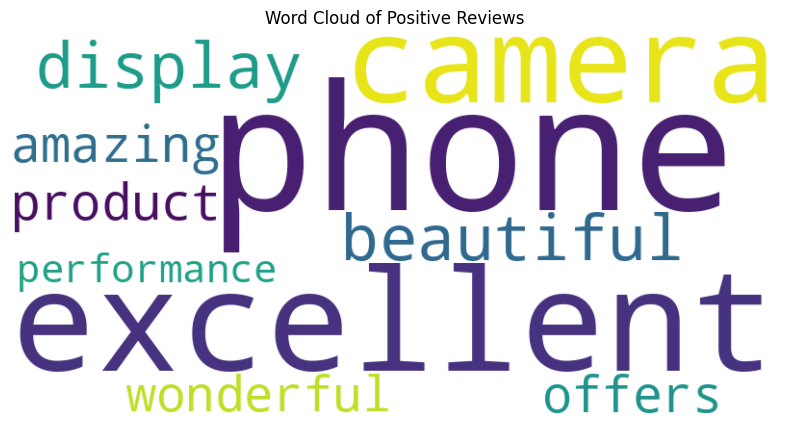

In [13]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_reviews = df[df["Sentiment"] == "Positive"]["Review"]
positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


In [14]:

# Q6
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense

training_text = """
Technology changes the way people learn work and communicate every day.
Smart tools help students explore ideas and practice new skills.
A computer can organize information while a human makes creative decisions.
People use technology to solve problems and share knowledge with others.
Learning becomes easier when information is clear and accessible.
Small projects teach useful lessons about patience teamwork and curiosity.
Each experiment offers a chance to test an idea and improve it.
Responsible technology respects privacy protects data and supports human needs.
The best innovations make daily tasks simpler and give people more time to create.
With careful design technology can build a better future for everyone.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

tokens = tokenizer.texts_to_sequences([training_text])[0]
vocab_size = len(tokenizer.word_index) + 1

sequences = []

for i in range(1, len(tokens)):
    sequences.append(tokens[max(0, i - 5):i + 1])

X = pad_sequences([seq[:-1] for seq in sequences], maxlen=5)
y = np.array([seq[-1] for seq in sequences])

print("Vocabulary Size:", vocab_size)
print("Input Shape:", X.shape)


Vocabulary Size: 88
Input Shape: (108, 5)


In [15]:

model = Sequential([
    Embedding(vocab_size, 32, input_shape=(5,)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(vocab_size, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history = model.fit(X, y, epochs=150, verbose=0)

print("Model trained successfully.")
print("Final Accuracy:", round(history.history['accuracy'][-1], 4))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model trained successfully.
Final Accuracy: 1.0


In [16]:

def generate_text(seed, next_words=12):
    text = seed

    for _ in range(next_words):
        sequence = tokenizer.texts_to_sequences([text])[0]
        sequence = pad_sequences([sequence], maxlen=5)

        predicted = np.argmax(model.predict(sequence, verbose=0), axis=1)[0]

        if predicted == 0:
            break

        text += " " + tokenizer.index_word[predicted]

    return text

seeds = ["technology", "people", "learning"]

for seed in seeds:
    print(generate_text(seed))


technology changes the way people learn work and communicate every day smart tools
people changes the way people learn work and communicate every day smart tools
learning changes the way people learn work and communicate every day smart tools
